# 03 — XGBoost

**Goal.** Train, tune, evaluate, and persist a XGBoost model for used-car resale price prediction on the synthetic Indian dataset.

**How this model works.** XGBoost builds trees sequentially, with each tree correcting the errors of the previous ensemble using gradient boosting and regularisation. The pipeline uses target encoding for the high-cardinality model key and one-hot encoding for low-cardinality categories.

**Why it suits this data.** Boosted trees are well suited to mixed tabular data and multiplicative price rules. Early stopping controls overfitting while retaining sharp thresholds such as the Delhi-NCR restriction.

All preprocessing, splits, and metrics come from `src/` so this notebook is directly comparable with the other five models and the dashboard.


In [1]:
from pathlib import Path
import sys, warnings, json
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn import set_config

set_config(display="diagram")
from src import config, data, features, metrics, plots, training, notebook_helpers as nh

plots.set_style()
nh.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "xgboost"
LABEL = config.MODEL_LABELS[MODEL_NAME]
print(f"Model: {LABEL} | seed={config.SEED} | reference year={config.REF_YEAR}")

Model: XGBoost | seed=42 | reference year=2026


## 1. Load data, validation report, and canonical split

The validation report fails loudly on nulls, duplicates, invalid prices, EV displacement errors, impossible fuel/transmission combinations, or purchase years before manufacturing. The saved split indices are reused by every notebook, and the 100k tuning subsample comes only from the training rows.

In [2]:
raw = data.load_raw_data()
validation_report = data.validate_data(raw)
train, val, test = data.split_frames(raw)
tuning = data.get_tuning_sample(train)
print(f'Tuning sample: {len(tuning):,} rows (train only)')

{
  "rows": 500000,
  "columns": 17,
  "null_counts": {},
  "duplicate_car_ids": 0,
  "duplicate_full_rows": 0,
  "non_positive_resale_prices": 0,
  "resale_ge_original": 0,
  "ev_nonzero_cc": 0,
  "non_ev_zero_cc": 0,
  "purchase_before_manufacture": 0,
  "impossible_fuel_transmission": 0,
  "impossible_combos": [],
  "valid": true,
  "issues": []
}


Split sizes -> train: 350,000 | val: 75,000 | test: 75,000
Tuning sample: 100,000 rows (train only)


## 2. Preprocessing pipeline

The diagram below is the actual sklearn pipeline saved in the artifact. It accepts a raw dataframe row, adds tuned-safe engineered features (Age, Ownership_Age, Km_Per_Year, train-fitted Km_Ratio, Delhi flags, ordinal encodings), then applies model-specific encoding. The target is trained as `log1p(Resale_Price_INR)`.

In [3]:
baseline_pipeline = training.build_pipeline(MODEL_NAME, dict(config.DEFAULT_PARAMS[MODEL_NAME]))
display(baseline_pipeline)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,add_interactions,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('low_card', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

## 3. Baseline fit and Optuna tuning

A default-parameter baseline is fitted first on the tuning sample. Optuna then explores 30–40 trials, minimizing validation RMSE on log price. The tuning sample is split into fit / early-stop / objective rows; the official validation and test sets are never used here.

In [4]:
study, best_params, baseline_metrics, tuning_meta = training.tune_model(
    MODEL_NAME, tuning, config.N_OPTUNA_TRIALS[MODEL_NAME]
)
display(pd.DataFrame(study.trials_dataframe().sort_values('value').head(10)))

Baseline validation metrics:
{
  "r2_log": 0.9965504338804132,
  "rmse_log": 0.06207206373954193,
  "mae_log": 0.04854830916513391,
  "mae_inr": 55018.00068445054,
  "rmse_inr": 119976.25831201457,
  "mape": 4.864380565602697,
  "median_ape": 3.9845830151199078
}


Best validation log-RMSE: 0.065954
Best params: {
  "learning_rate": 0.010461332205410167,
  "max_depth": 12,
  "min_child_weight": 3.6731132599351297,
  "subsample": 0.8913347480456725,
  "colsample_bytree": 0.7986287431517634,
  "reg_lambda": 0.002752935916667012,
  "reg_alpha": 0.05964558948770788,
  "gamma": 0.01070493668762465,
  "te_smooth": 25.786022178004036,
  "best_iteration": 2489
}


,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_reg_alpha,params_reg_lambda,params_subsample,params_te_smooth,user_attrs_best_iteration,system_attrs_tpe:relative_params:0,state
37,37,0.065954,2026-10-21 20:47:15.936704,2026-10-21 20:47:48.501150,0 days 00:00:32.564446,0.798629,0.010705,0.010461,12,3.673113,0.059646,0.002753,0.891335,25.786022,2489,"{""colsample_bytree"": 0.7986287431517634, ""gamm...",COMPLETE
21,21,0.066450,2026-10-21 20:44:02.864058,2026-10-21 20:44:28.451524,0 days 00:00:25.587466,0.872300,0.029617,0.012358,11,6.560929,0.002869,0.007443,0.874187,37.910783,2484,"{""colsample_bytree"": 0.8723002823680837, ""gamm...",COMPLETE
38,38,0.067963,2026-10-21 20:47:48.501226,2026-10-21 20:48:09.467641,0 days 00:00:20.966415,0.855772,0.058810,0.014449,10,17.070021,0.003818,0.007039,0.882424,19.391828,2315,"{""colsample_bytree"": 0.8557722891197911, ""gamm...",COMPLETE
18,18,0.070086,2026-10-21 20:43:23.846942,2026-10-21 20:43:45.946942,0 days 00:00:22.100000,0.874540,0.057327,0.011320,12,6.870014,0.138833,0.015603,0.959309,31.637096,1618,"{""colsample_bytree"": 0.8745398807098613, ""gamm...",COMPLETE
27,27,0.070770,2026-10-21 20:45:18.735584,2026-10-21 20:45:36.161776,0 days 00:00:17.426192,0.759150,0.121265,0.012436,11,8.386912,0.012400,0.007659,0.947865,18.348920,1455,"{""colsample_bytree"": 0.7591504884643512, ""gamm...",COMPLETE
35,35,0.071094,2026-10-21 20:46:51.862397,2026-10-21 20:47:06.158336,0 days 00:00:14.295939,0.802678,0.124902,0.013113,11,7.723932,0.005378,0.002257,0.915547,21.799391,1178,"{""colsample_bytree"": 0.8026781051905502, ""gamm...",COMPLETE
28,28,0.072007,2026-10-21 20:45:36.161852,2026-10-21 20:45:48.521054,0 days 00:00:12.359202,0.793524,0.098082,0.019349,12,14.803990,0.009281,0.011875,0.910253,28.867801,1179,"{""colsample_bytree"": 0.7935241388825014, ""gamm...",COMPLETE
39,39,0.072760,2026-10-21 20:48:09.467712,2026-10-21 20:48:23.998064,0 days 00:00:14.530352,0.771848,0.161439,0.013634,12,2.081274,0.060647,0.007237,0.928659,33.003910,1318,"{""colsample_bytree"": 0.771847572084388, ""gamma...",COMPLETE
25,25,0.075540,2026-10-21 20:44:58.331634,2026-10-21 20:45:09.376298,0 days 00:00:11.044664,0.861240,0.271193,0.016292,10,8.716961,0.005610,0.025333,0.912844,8.099504,1063,"{""colsample_bytree"": 0.8612398123541714, ""gamm...",COMPLETE
15,15,0.078273,2026-10-21 20:42:44.758084,2026-10-21 20:43:00.126825,0 days 00:00:15.368741,0.884345,0.386804,0.012547,11,7.892278,0.007489,0.026633,0.944475,13.267040,1088,"{""colsample_bytree"": 0.8843449380234663, ""gamm...",COMPLETE


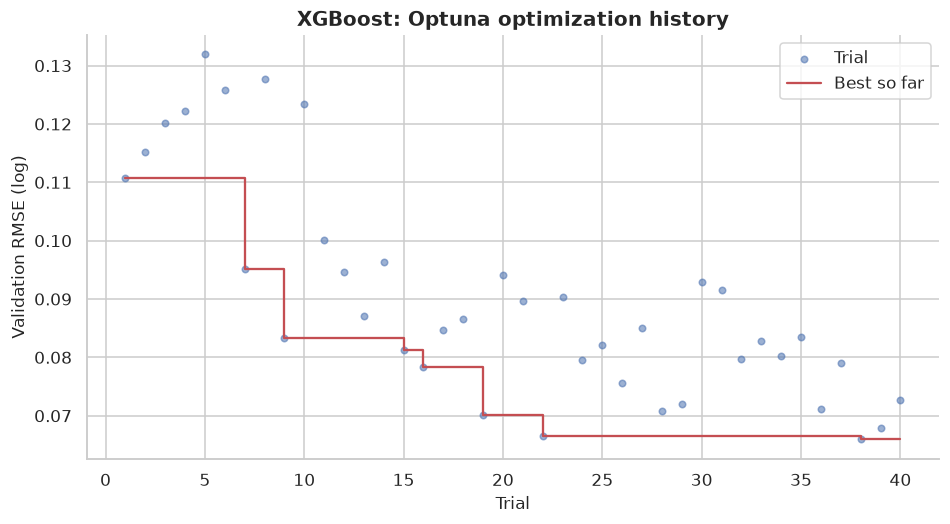

In [5]:
fig = plots.plot_optuna_history(study, f'{LABEL}: Optuna optimization history')
fig.savefig(nh.FIGURES_DIR / f'{MODEL_NAME}_optuna_history.png', dpi=110, bbox_inches='tight')
plt.show()

## 4. Final training and timing

The best parameters are refitted on the full 350k-row training split. For boosted models the iteration count selected by early stopping is reused; the test set is only touched for the final evaluation below.

In [6]:
final_pipeline, train_time_s = training.train_final_model(MODEL_NAME, best_params, train)
evaluation = nh.predict_eval(final_pipeline, val, test)
print(f'Final train time: {train_time_s:.2f}s')
print(f'Inference: {evaluation["inference_ms_per_1k"]:.2f} ms per 1,000 rows')

Final train time: 169.29s
Inference: 113.43 ms per 1,000 rows


## 5. Validation and test metrics

The generator injects roughly 4.5% log-normal noise, so a test MAPE near 4–6% is the realistic target. Metrics far below that would trigger a leakage investigation before accepting the model.

In [7]:
display(nh.metrics_frame(evaluation['val_metrics'], evaluation['test_metrics']))
print('Noise-floor note:', '~4.5% log-normal generator noise; MAPE near 4-6% is expected.')

,Validation,Test
Metric,,
R² (log),0.99743,0.99746
RMSE (log),0.05347,0.05328
MAE (log),0.04224,0.04215
MAE (INR),"₹47,062","₹47,360"
RMSE (INR),"₹98,485","₹1,00,281"
MAPE,4.23%,4.22%
Median APE,3.54%,3.52%


Noise-floor note: ~4.5% log-normal generator noise; MAPE near 4-6% is expected.


## 6. Diagnostic plots

The plots cover calibration, residuals, error segments, feature importance, SHAP (tree models only), partial dependence for Age / Kilometres / Condition, and a learning or loss curve.

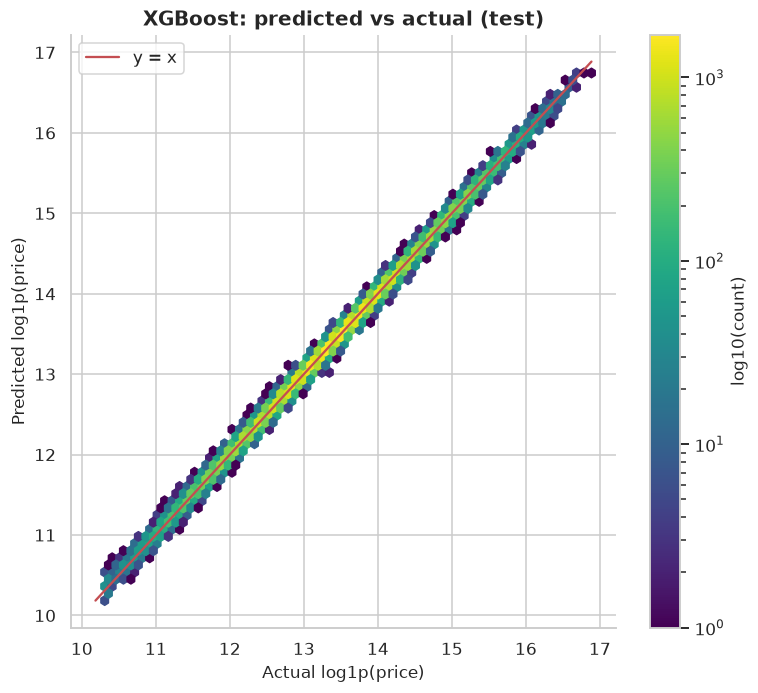

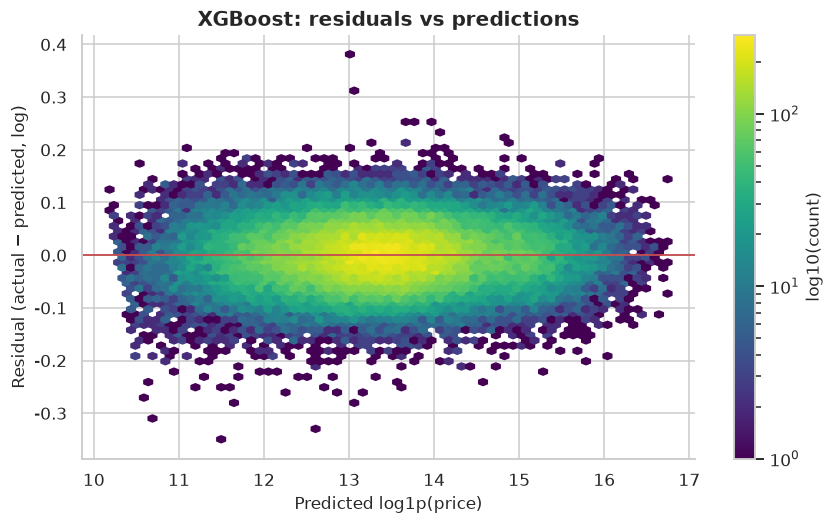

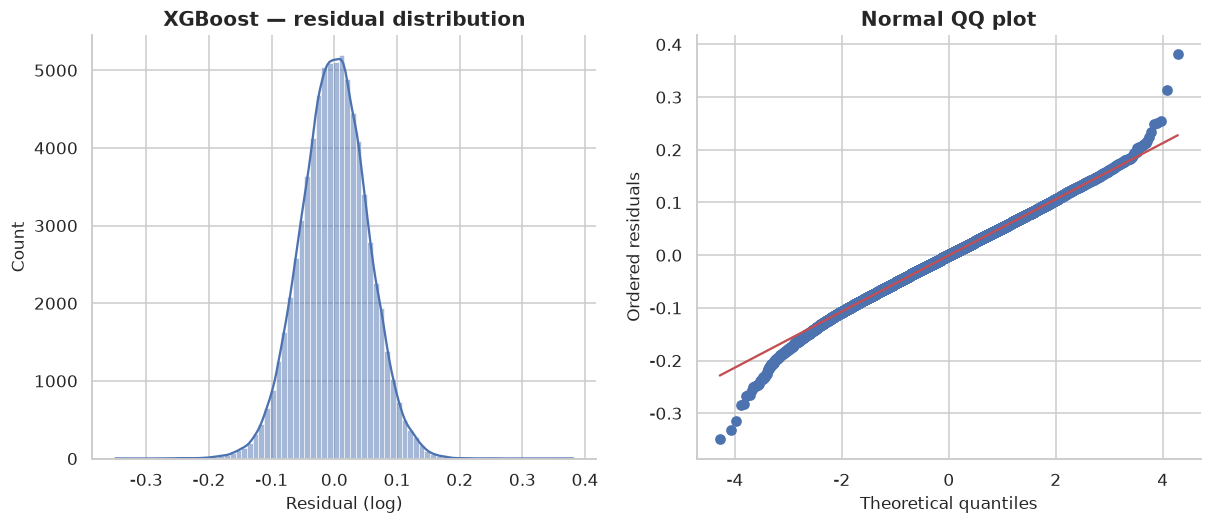

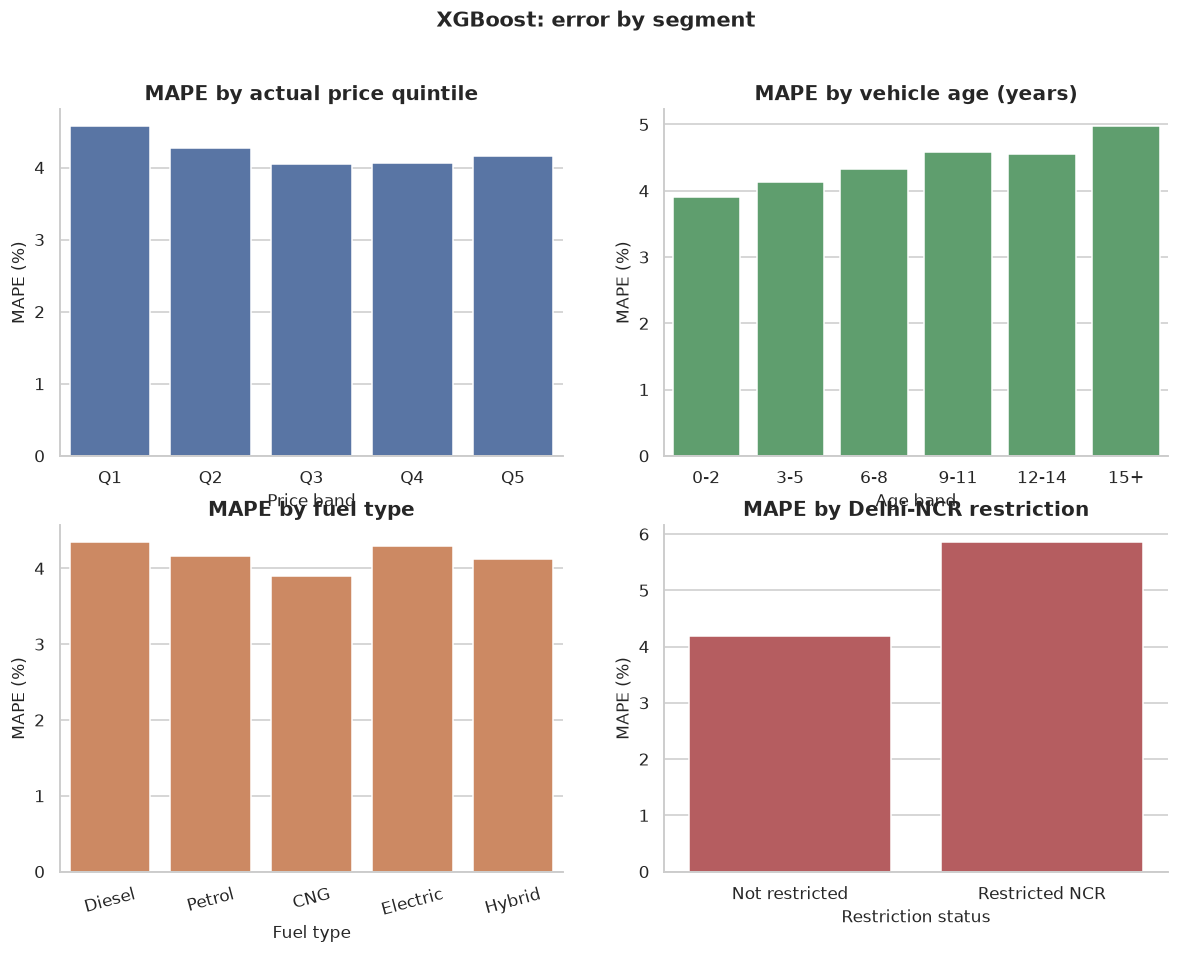

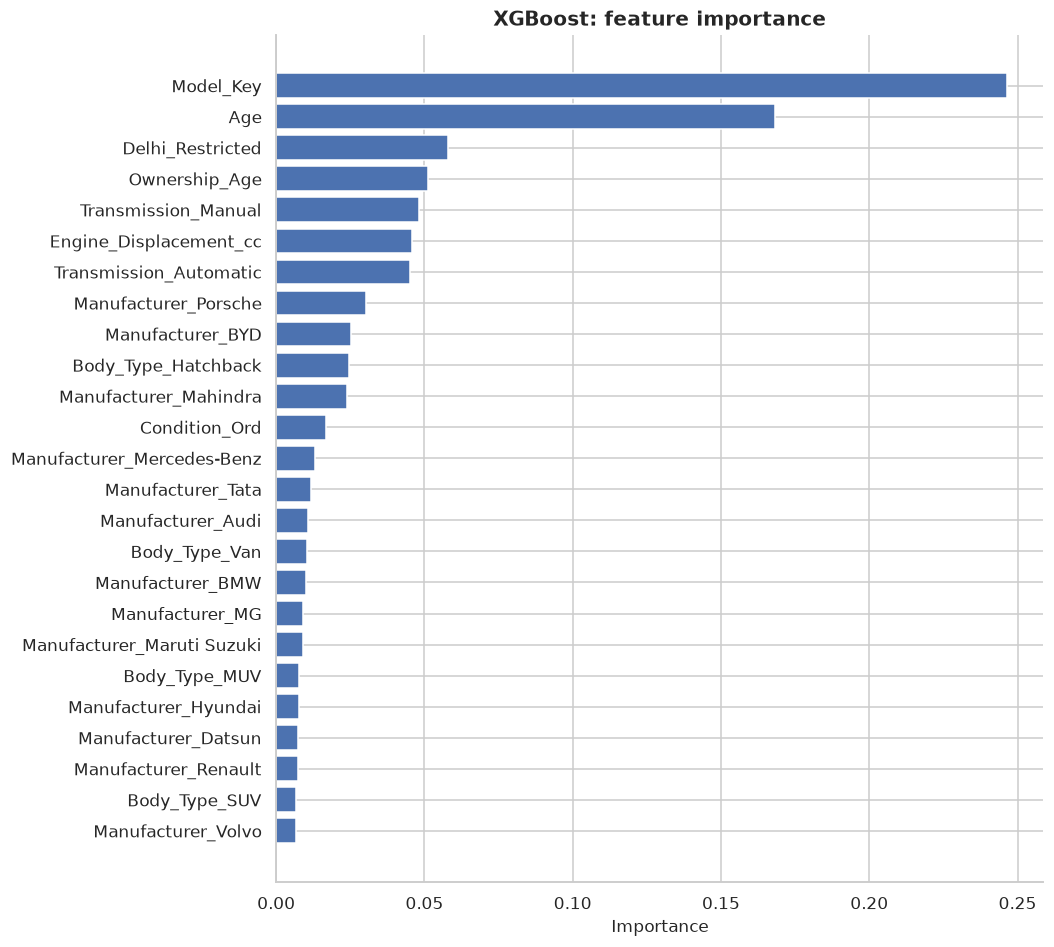

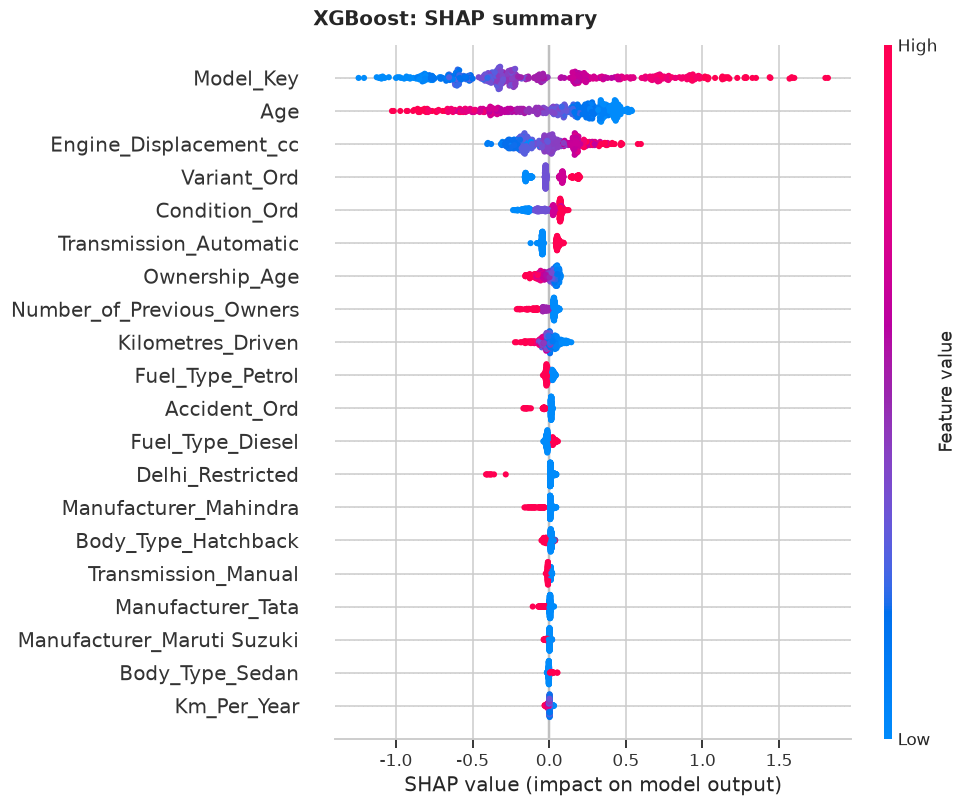

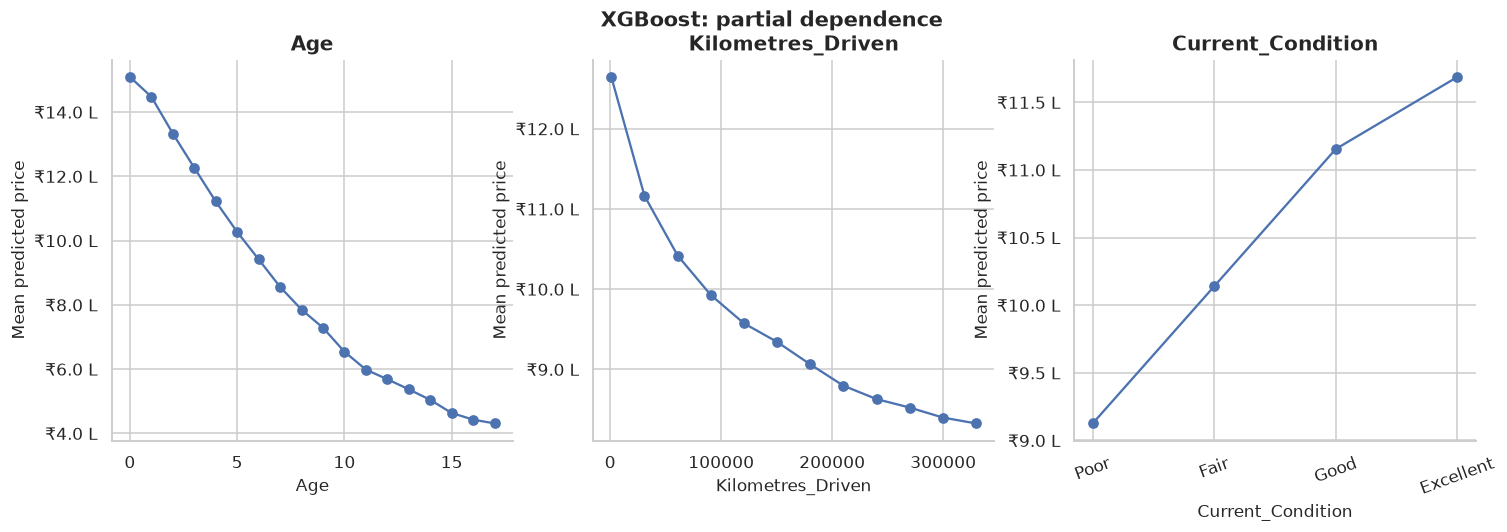

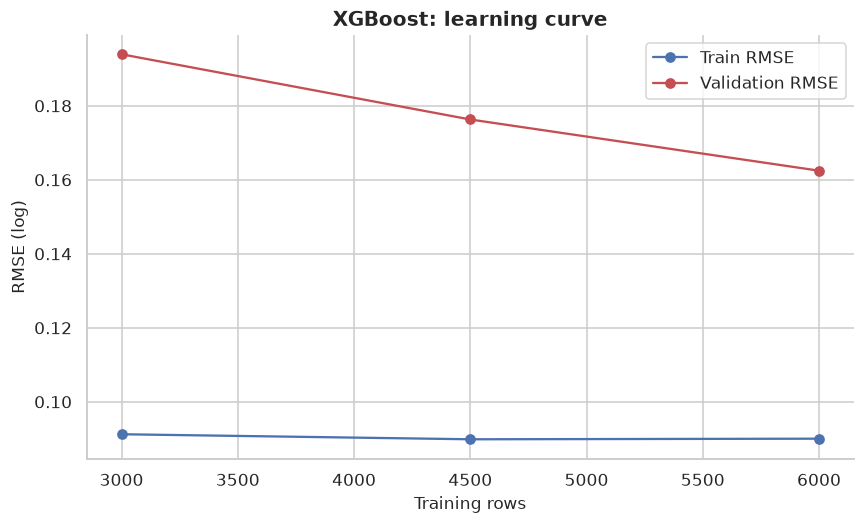

In [8]:
nh.run_standard_plots(
    MODEL_NAME, final_pipeline, best_params, train, val, test, evaluation['test_log']
)

## 7. Sanity checks

Holding other inputs fixed, prices should trend down with age and kilometres. EVs must use zero displacement, and predicted resale should stay below the original purchase price where that column is available.

In [9]:
sanity = nh.sanity_report(MODEL_NAME, final_pipeline, test)

                      Check                                             Result Status
           Age monotonicity Spearman ρ=-1.000; 100.0% of age steps lower price   pass
    Kilometres monotonicity  Spearman ρ=-1.000; 100.0% of km steps lower price   pass
                    EV rows              n=2,241; MAPE=4.30%; RMSE(log)=0.0542   pass
Predicted resale < original   100.00% predicted below original; actual 100.00%   pass


## 8. Save model and append metrics

The raw-input sklearn pipeline is serialized to `artifacts/<model>.joblib`; tuned parameters and validation/test metrics are written to `artifacts/<model>_params.json` and `artifacts/metrics.json`.

In [10]:
payload = nh.save_and_report(
    MODEL_NAME, final_pipeline, best_params, baseline_metrics, tuning_meta,
    evaluation, train_time_s
)

Saved artifact and appended metrics:
{
  "model_label": "XGBoost",
  "use_original_price": false,
  "val": {
    "r2_log": 0.9974325565139837,
    "rmse_log": 0.05346601849037105,
    "mae_log": 0.04224477141808126,
    "mae_inr": 47061.733493179585,
    "rmse_inr": 98485.144110333,
    "mape": 4.232345864979721,
    "median_ape": 3.5412965836969734
  },
  "test": {
    "r2_log": 0.9974622190334652,
    "rmse_log": 0.053275643626556755,
    "mae_log": 0.04215102022410429,
    "mae_inr": 47359.79674444559,
    "rmse_inr": 100281.08507833448,
    "mape": 4.223204386473997,
    "median_ape": 3.516105500892994
  },
  "baseline_val": {
    "r2_log": 0.9965504338804132,
    "rmse_log": 0.06207206373954193,
    "mae_log": 0.04854830916513391,
    "mae_inr": 55018.00068445054,
    "rmse_inr": 119976.25831201457,
    "mape": 4.864380565602697,
    "median_ape": 3.9845830151199078
  },
  "tuning": {
    "n_trials": 40,
    "best_value_log_rmse": 0.06595362673958508,
    "tuning_sample_rows": 100

## 9. Findings

**Strengths:** high accuracy, handles interactions, early stopping, and native missing/unseen-category handling. **Weaknesses:** more hyperparameters, slower tuning, and less interpretable than Ridge. **Largest errors:** very old restricted diesel cars, rare luxury models, and sparse fuel/transmission combinations.

The dashboard reads the model artifacts and `metrics.json`; it does not hardcode any winner.